# Genre Classification with Classic Machine Learning

This notebook predicts a song's genre from averaged GloVe vectors and asks whether adding TF-IDF word weights helps. The same four classic models are trained on two feature sets and compared on the same validation songs:

- **Feature sets:** `GloVe` (25 averaged embedding dimensions) and `GloVe + TF-IDF` (the same 25 dimensions plus 1000 TF-IDF columns), both created in `preprocessing_unified.ipynb`.
- **Models:** histogram gradient boosting, random forest, Gaussian naive Bayes and logistic regression.
- **Evaluation:** every run is analysed with `diagnose` from `utils/funcs.py` (scores, confusion matrix, scores per genre, predicted vs true genre share, ROC curves), followed by a direct comparison of the two feature sets.
- **Validation split:** the rows of the feature files follow `data/splits.parquet`, the shared stratified 25% split, so the results are comparable with the transformer models of the project.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
SEED = 80085

BALANCED = True   # True: class weights in the training loss (no resampling), False: plain loss
TRAIN = True      # False: load the saved predictions instead of training

In [3]:
# The project root, which holds data/ and models/. Adjusted if the notebook is run from a subfolder
project_dir = Path(".")
if not (project_dir / "data").exists() and (Path("..") / "data").exists():
    project_dir = Path("..")
sys.path.append(str(project_dir.resolve()))   # for the shared utils package

from utils.funcs import diagnose

data_dir = project_dir / "data"
glove_dir = data_dir / "data-GloVe"
classic_dir = data_dir / "data-Classic"
results_dir = project_dir / "models" / "classic"

## Loading the Data

Two datasets are loaded: the averaged GloVe vectors (`data-GloVe`) and the GloVe vectors combined with TF-IDF features (`data-Classic`). Both were created from the same songs in the same order, which is checked here: the row counts must match the `train` and `val` assignment in `data/splits.parquet`, and the genre labels of both files must be identical.

The test set is not needed for the model comparison.

In [4]:
splits = pl.read_parquet(data_dir / "splits.parquet")
n_train = splits.filter(pl.col("split") == "train").height
n_val = splits.filter(pl.col("split") == "val").height

glove_train = pl.read_csv(glove_dir / "train_glove.csv")
glove_val = pl.read_csv(glove_dir / "val_glove.csv")
both_train = pl.read_parquet(classic_dir / "train_glove_tfidf.parquet")
both_val = pl.read_parquet(classic_dir / "val_glove_tfidf.parquet")

assert glove_train.height == both_train.height == n_train, "train rows differ from splits.parquet"
assert glove_val.height == both_val.height == n_val, "validation rows differ from splits.parquet"
assert (glove_train["genre"] == both_train["genre"]).all(), "train labels differ between the two datasets"
assert (glove_val["genre"] == both_val["genre"]).all(), "validation labels differ between the two datasets"

print(f"train: {n_train:,}  validation: {n_val:,}")
print(f"GloVe: {glove_train.width - 1} features, GloVe + TF-IDF: {both_train.width - 1} features")

train: 100,893  validation: 33,632
GloVe: 25 features, GloVe + TF-IDF: 1025 features


The genres are used as text labels. Their distribution in the training and validation set is almost identical, since the split is stratified. The share of the biggest genre is the accuracy of a model that always guesses it, which every model has to beat. Because the genres are very imbalanced, **macro F1** (every genre counts equally) is the main metric, next to accuracy.

In [5]:
y_train = glove_train["genre"].to_numpy()
y_val = glove_val["genre"].to_numpy()
genres = np.unique(y_train)

(glove_train.select("genre").to_series().value_counts(normalize=True).rename({"proportion": "train"})
    .join(glove_val.select("genre").to_series().value_counts(normalize=True).rename({"proportion": "validation"}), on="genre")
    .with_columns(pl.col("train", "validation").round(3))
    .sort("train", descending=True))

genre,train,validation
str,f64,f64
"""pop""",0.412,0.412
"""rap""",0.286,0.286
"""rock""",0.188,0.188
"""rb""",0.046,0.046
"""misc""",0.042,0.042
"""country""",0.026,0.026


## Feature Sets

Both feature sets are converted to float32 matrices:

- `glove`: the 25 dimensions `dim_0` to `dim_24`, the mean GloVe vector of the tokens of a song.
- `glove_tfidf`: the same 25 dimensions plus the TF-IDF weights of the 1000 most frequent terms. The TF-IDF vocabulary was fitted on the training songs only.

Since the TF-IDF columns are appended to the GloVe columns, the second feature set contains the first one, and any difference in the results comes from the TF-IDF features alone.

In [6]:
glove_cols = [c for c in glove_train.columns if c != "genre"]
both_cols = [c for c in both_train.columns if c != "genre"]
assert both_cols[:len(glove_cols)] == glove_cols, "the GloVe columns must come first"

feature_sets = {
    "glove": (glove_train.select(glove_cols).to_numpy().astype(np.float32),
              glove_val.select(glove_cols).to_numpy().astype(np.float32)),
    "glove_tfidf": (both_train.select(both_cols).to_numpy().astype(np.float32),
                    both_val.select(both_cols).to_numpy().astype(np.float32)),
}
feature_names = {"glove": glove_cols, "glove_tfidf": both_cols}
labels = {"glove": "GloVe", "glove_tfidf": "GloVe + TF-IDF"}

del glove_train, glove_val, both_train, both_val
for key, (X_tr, X_v) in feature_sets.items():
    print(f"{labels[key]:15} train {X_tr.shape}  validation {X_v.shape}")

GloVe           train (100893, 25)  validation (33632, 25)
GloVe + TF-IDF  train (100893, 1025)  validation (33632, 1025)


## Models

Four classic models are trained, each on both feature sets with identical settings:

- **Histogram gradient boosting** builds trees one after another, each correcting the errors of the previous ones, on binned features. It stops early when the score on 10% of the training data no longer improves, so it does not use the shared validation set for training decisions.
- **Random forest** averages 300 decorrelated trees. `min_samples_leaf=5` limits how closely single trees can memorise the training songs.
- **Gaussian naive Bayes** assumes that every feature is normally distributed within a genre and independent of the others. The multinomial variant cannot be used, because GloVe values can be negative. The skewed, sparse TF-IDF columns violate the normal assumption, so this model is expected to profit least from them.
- **Logistic regression** is a linear model, the regression baseline. The features are standardised first, because GloVe dimensions and TF-IDF weights live on very different scales, which would slow down and distort the optimisation.

**Class weights.** The genres are very imbalanced. With `BALANCED = True` the loss of the models is weighted by the inverse genre frequency (`"balanced"` weights of scikit-learn), the same idea as the weighted loss of the transformer notebook. The data itself is not resampled, and the validation set keeps its real distribution. Gaussian naive Bayes has no class weights and keeps its learned genre priors.

In [ ]:
def make_models():
    """Fresh, unfitted models, so that every feature set gets its own copy."""
    weight = "balanced" if BALANCED else None
    return {
        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, min_samples_leaf=50, l2_regularization=0.1,
            early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
            class_weight=weight, random_state=SEED),
        "RandomForest": RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5,
            class_weight="balanced_subsample" if BALANCED else None,
            n_jobs=-1, random_state=SEED),
        "NaiveBayes": GaussianNB(),
        "LogisticRegression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=500, class_weight=weight, random_state=SEED)),
    }

model_keys = list(make_models())
model_keys

['HistGradientBoosting', 'RandomForest', 'NaiveBayes', 'LogisticRegression']

## Training

Every model is fitted on the training songs of each feature set (4 models × 2 feature sets = 8 runs). For every run the notebook keeps the validation probabilities, the training accuracy and the fit time, which is everything the evaluation needs. For the random forest, the feature importances of both feature sets are kept as well.

**Saving.** The results are written to `models/classic/` (`val_proba.npz`, `runs.json`), a few megabytes in total, instead of the fitted models, which can be several hundred megabytes for the random forests.

**Switch.** `TRAIN = False` skips the training and loads the saved results, so the evaluation can be run again without refitting anything.

In [ ]:
def fit_all():
    runs, importances = {}, {}
    for fs_key, (X_tr, X_v) in feature_sets.items():
        for m_key, model in make_models().items():
            start = time.time()
            model.fit(X_tr, y_train)
            fit_seconds = round(time.time() - start, 1)
            assert list(model.classes_) == list(genres), "class order differs from the genre list"
            runs[(fs_key, m_key)] = {"proba": model.predict_proba(X_v),
                                     "train_accuracy": float(model.score(X_tr, y_train)),
                                     "fit_seconds": fit_seconds}
            if m_key == "RandomForest":
                importances[fs_key] = model.feature_importances_
            print(f"{labels[fs_key]:15} {m_key:22} fitted in {fit_seconds:>6.1f}s")
    return runs, importances

def save_runs(runs, importances):
    results_dir.mkdir(parents=True, exist_ok=True)
    arrays = {f"{fs}__{m}": r["proba"] for (fs, m), r in runs.items()}
    arrays.update({f"importance__{fs}": v for fs, v in importances.items()})
    np.savez_compressed(results_dir / "val_proba.npz", **arrays)
    meta = {f"{fs}__{m}": {"train_accuracy": r["train_accuracy"], "fit_seconds": r["fit_seconds"]}
            for (fs, m), r in runs.items()}
    (results_dir / "runs.json").write_text(json.dumps(meta, indent=2))


def load_runs():
    arrays = np.load(results_dir / "val_proba.npz")
    meta = json.loads((results_dir / "runs.json").read_text())
    runs = {}
    for key, scalars in meta.items():
        fs_key, m_key = key.split("__")
        runs[(fs_key, m_key)] = {"proba": arrays[key], **scalars}
    importances = {k.split("__")[1]: arrays[k] for k in arrays.files if k.startswith("importance__")}
    return runs, importances

In [9]:
if TRAIN:
    runs, importances = fit_all()
    save_runs(runs, importances)
else:
    runs, importances = load_runs()

pl.DataFrame([{"features": labels[fs], "model": m,
               "train_accuracy": round(r["train_accuracy"], 3), "fit_seconds": r["fit_seconds"]}
              for (fs, m), r in runs.items()])

GloVe           HistGradientBoosting   fitted in    5.9s
GloVe           RandomForest           fitted in   38.6s
GloVe           NaiveBayes             fitted in    0.2s
GloVe           LogisticRegression     fitted in   20.4s
GloVe + TF-IDF  HistGradientBoosting   fitted in  182.8s
GloVe + TF-IDF  RandomForest           fitted in   54.7s
GloVe + TF-IDF  NaiveBayes             fitted in    1.3s
GloVe + TF-IDF  LogisticRegression     fitted in  745.5s


features,model,train_accuracy,fit_seconds
str,str,f64,f64
"""GloVe""","""HistGradientBoosting""",0.515,5.9
"""GloVe""","""RandomForest""",0.923,38.6
"""GloVe""","""NaiveBayes""",0.378,0.2
"""GloVe""","""LogisticRegression""",0.424,20.4
"""GloVe + TF-IDF""","""HistGradientBoosting""",0.6,182.8
"""GloVe + TF-IDF""","""RandomForest""",0.913,54.7
"""GloVe + TF-IDF""","""NaiveBayes""",0.39,1.3
"""GloVe + TF-IDF""","""LogisticRegression""",0.512,745.5


## Evaluation

Every run is analysed with `diagnose` (`utils/funcs.py`), which prints the headline scores and draws four plots for one classifier:

1. the **confusion matrix**, normalised per true genre, so the diagonal is the recall of each genre,
2. **precision, recall and F1 per genre**, with the number of validation songs,
3. the **true vs predicted share** of every genre, which shows whether a model over or under predicts the big genres,
4. one vs rest **ROC curves** with their AUC, and their macro average.

The headline scores report the validation accuracy next to the accuracy of always guessing the biggest genre, the training accuracy, macro F1 and weighted F1. `diagnose` returns these scores, which are collected in `scores` for the comparison at the end.

Each model is evaluated on both feature sets, `GloVe` first.

In [10]:
scores = {}

def evaluate(fs_key, m_key):
    r = runs[(fs_key, m_key)]
    scores[(fs_key, m_key)] = diagnose(
        y_val, r["proba"], genres,
        name=f"{m_key} on {labels[fs_key]}",
        train_accuracy=r["train_accuracy"])

### Histogram Gradient Boosting

train accuracy: 0.515
val accuracy:   0.462  (always guessing the biggest genre: 0.412)
macro F1:       0.402
weighted F1:    0.474
              precision    recall  f1-score   support

     country       0.10      0.52      0.17       865
        misc       0.36      0.63      0.46      1398
         pop       0.66      0.21      0.32     13870
         rap       0.81      0.76      0.79      9632
          rb       0.15      0.54      0.24      1548
        rock       0.39      0.48      0.43      6319

    accuracy                           0.46     33632
   macro avg       0.41      0.53      0.40     33632
weighted avg       0.60      0.46      0.47     33632



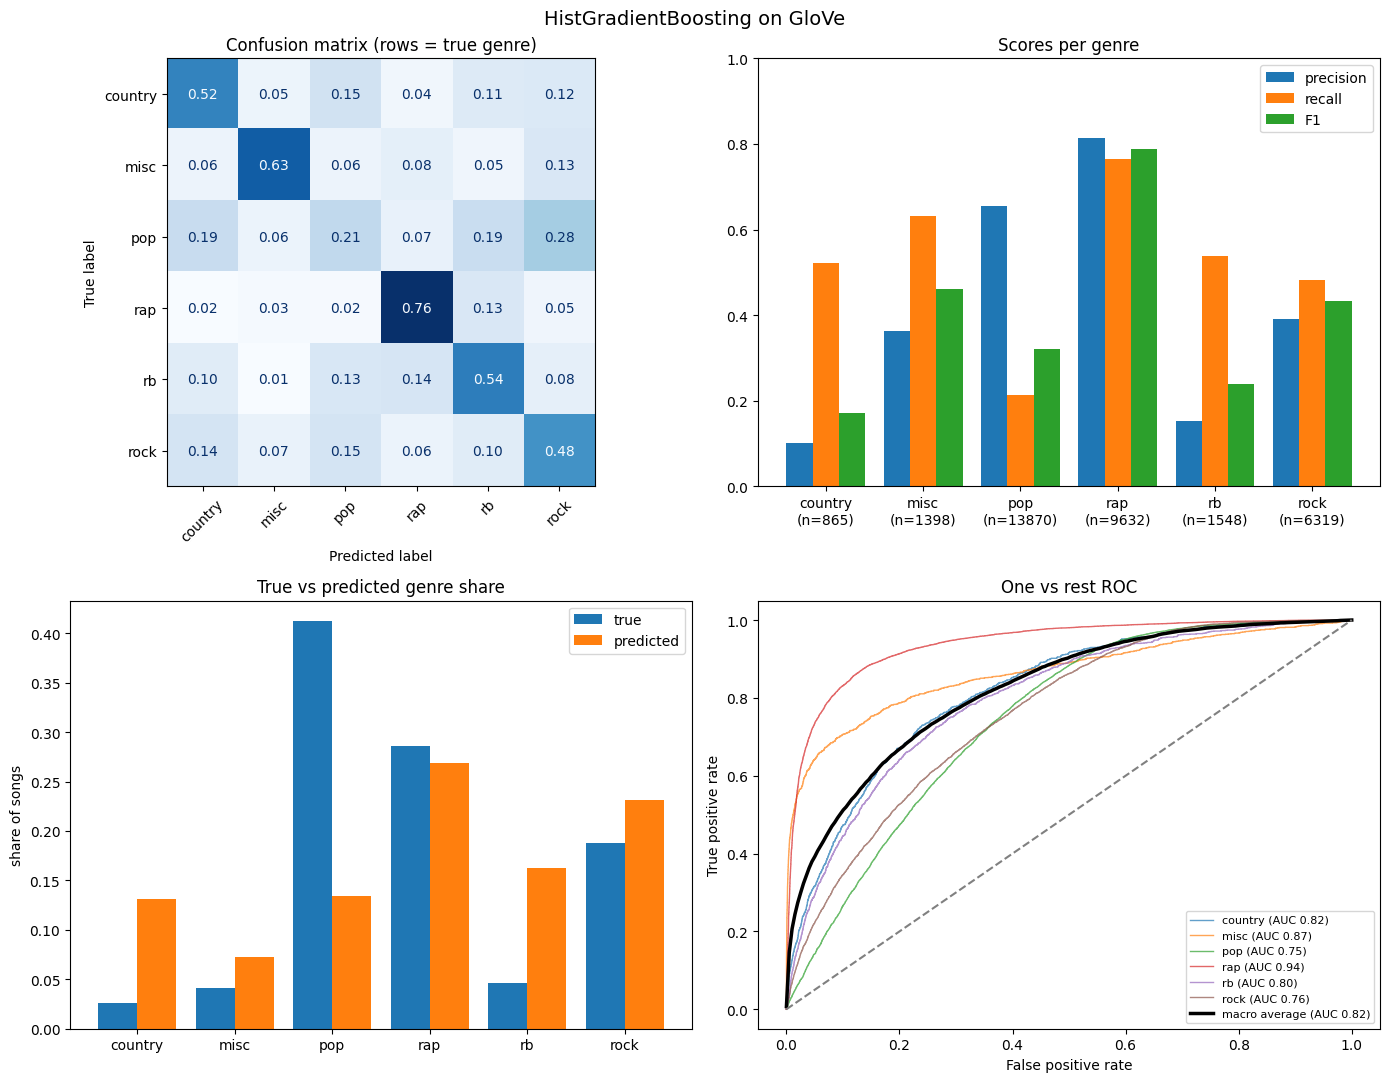

train accuracy: 0.600
val accuracy:   0.528  (always guessing the biggest genre: 0.412)
macro F1:       0.457
weighted F1:    0.543
              precision    recall  f1-score   support

     country       0.15      0.57      0.24       865
        misc       0.40      0.64      0.49      1398
         pop       0.66      0.32      0.43     13870
         rap       0.87      0.81      0.84      9632
          rb       0.19      0.53      0.28      1548
        rock       0.42      0.53      0.47      6319

    accuracy                           0.53     33632
   macro avg       0.45      0.57      0.46     33632
weighted avg       0.63      0.53      0.54     33632



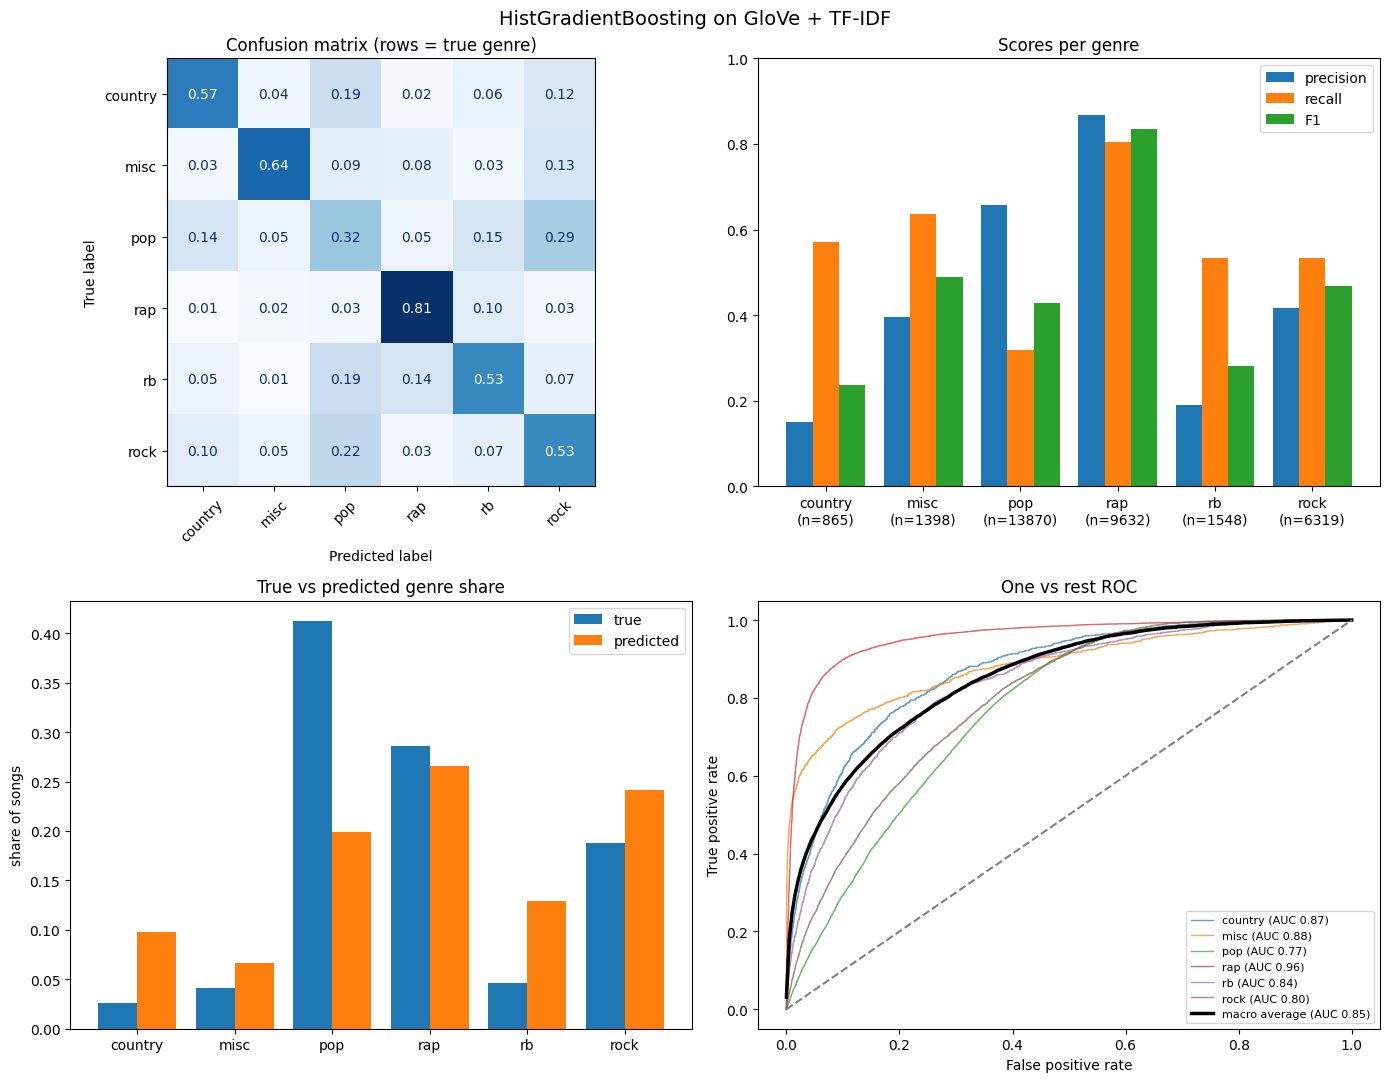

In [11]:
for fs_key in feature_sets:
    evaluate(fs_key, "HistGradientBoosting")

### Random Forest

train accuracy: 0.923
val accuracy:   0.619  (always guessing the biggest genre: 0.412)
macro F1:       0.445
weighted F1:    0.600
              precision    recall  f1-score   support

     country       0.26      0.06      0.10       865
        misc       0.54      0.56      0.55      1398
         pop       0.60      0.70      0.65     13870
         rap       0.77      0.84      0.80      9632
          rb       0.27      0.16      0.20      1548
        rock       0.44      0.32      0.37      6319

    accuracy                           0.62     33632
   macro avg       0.48      0.44      0.44     33632
weighted avg       0.59      0.62      0.60     33632



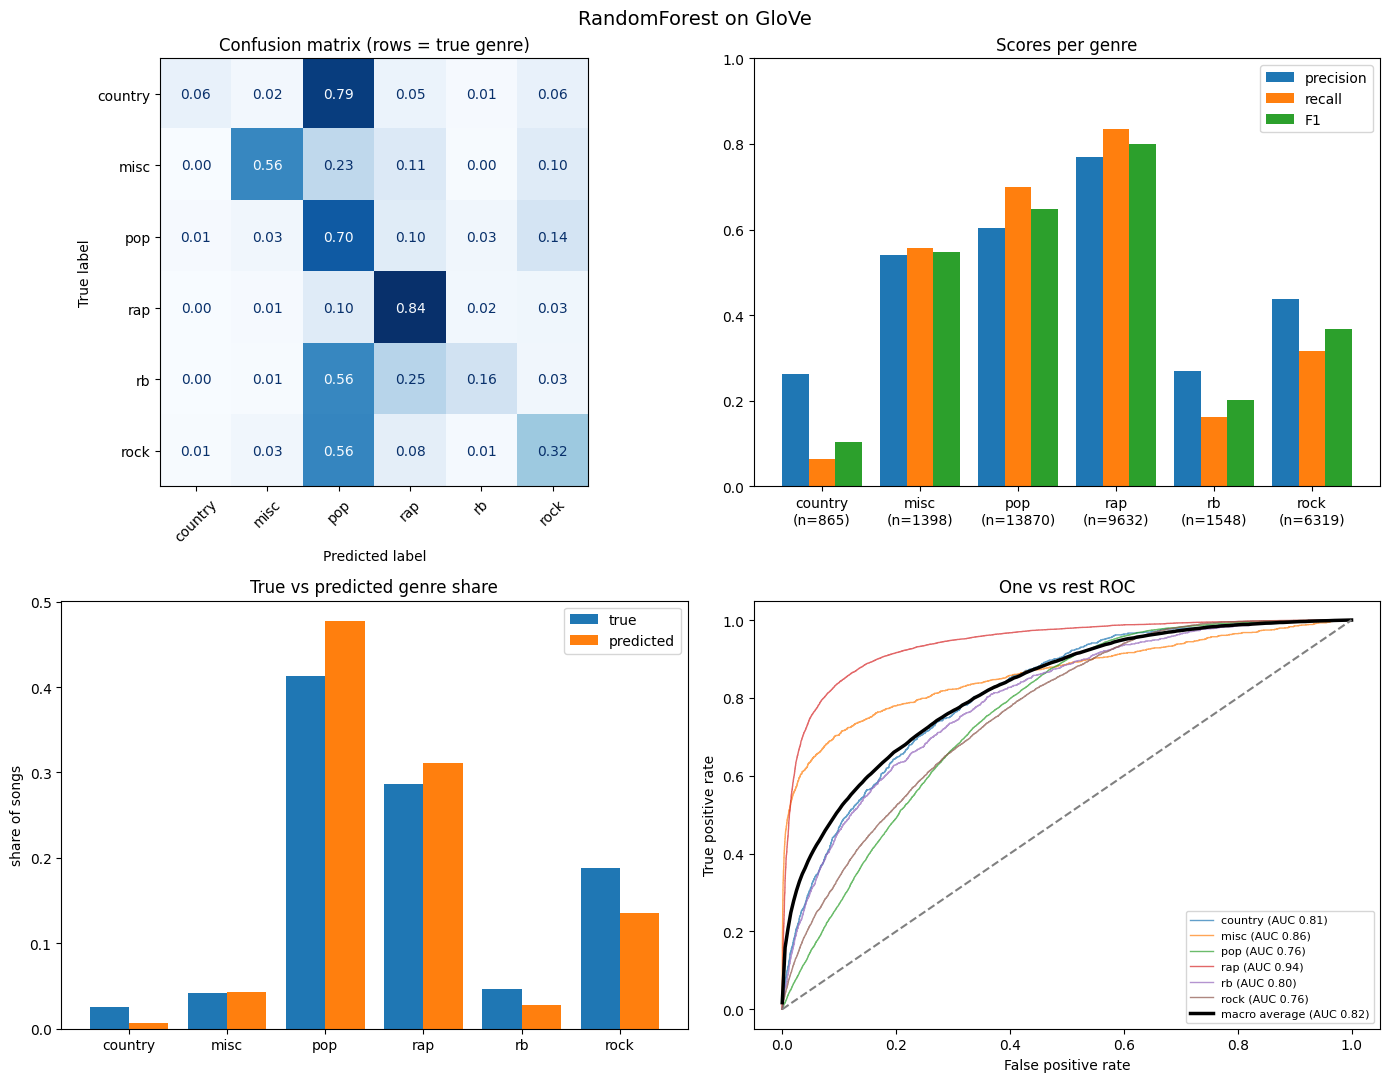

train accuracy: 0.913
val accuracy:   0.629  (always guessing the biggest genre: 0.412)
macro F1:       0.452
weighted F1:    0.613
              precision    recall  f1-score   support

     country       0.29      0.03      0.05       865
        misc       0.53      0.57      0.55      1398
         pop       0.61      0.69      0.65     13870
         rap       0.80      0.85      0.82      9632
          rb       0.30      0.20      0.24      1548
        rock       0.45      0.35      0.39      6319

    accuracy                           0.63     33632
   macro avg       0.50      0.45      0.45     33632
weighted avg       0.61      0.63      0.61     33632



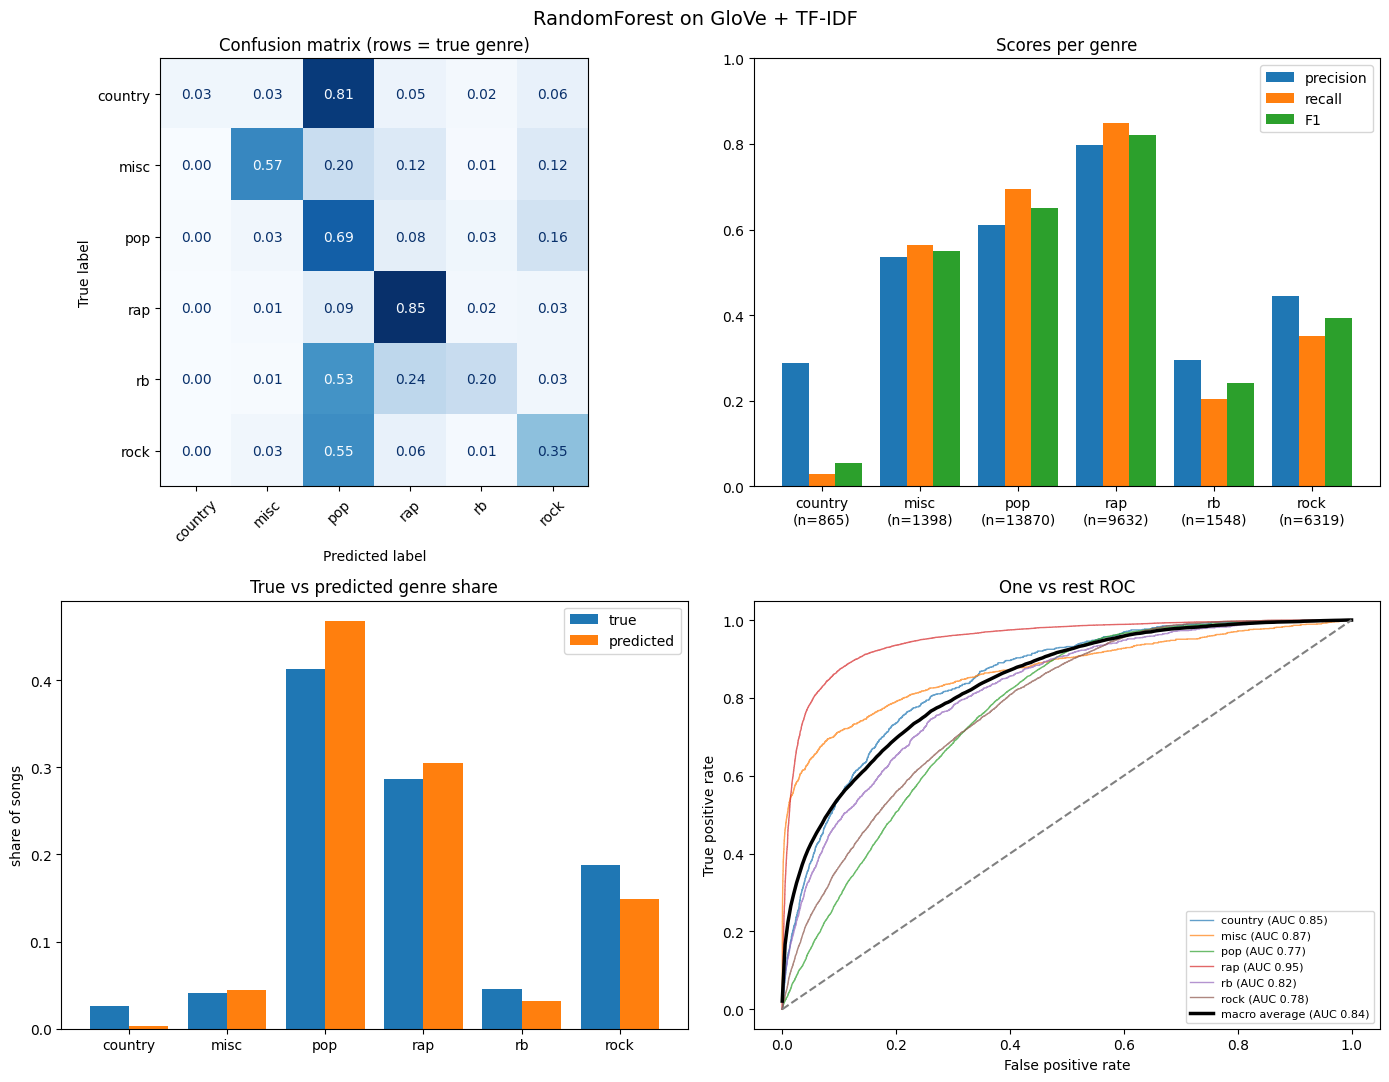

In [12]:
for fs_key in feature_sets:
    evaluate(fs_key, "RandomForest")

### Gaussian Naive Bayes

train accuracy: 0.378
val accuracy:   0.379  (always guessing the biggest genre: 0.412)
macro F1:       0.299
weighted F1:    0.403
              precision    recall  f1-score   support

     country       0.14      0.05      0.08       865
        misc       0.19      0.62      0.29      1398
         pop       0.58      0.24      0.34     13870
         rap       0.71      0.65      0.68      9632
          rb       0.09      0.64      0.16      1548
        rock       0.35      0.19      0.24      6319

    accuracy                           0.38     33632
   macro avg       0.34      0.40      0.30     33632
weighted avg       0.52      0.38      0.40     33632



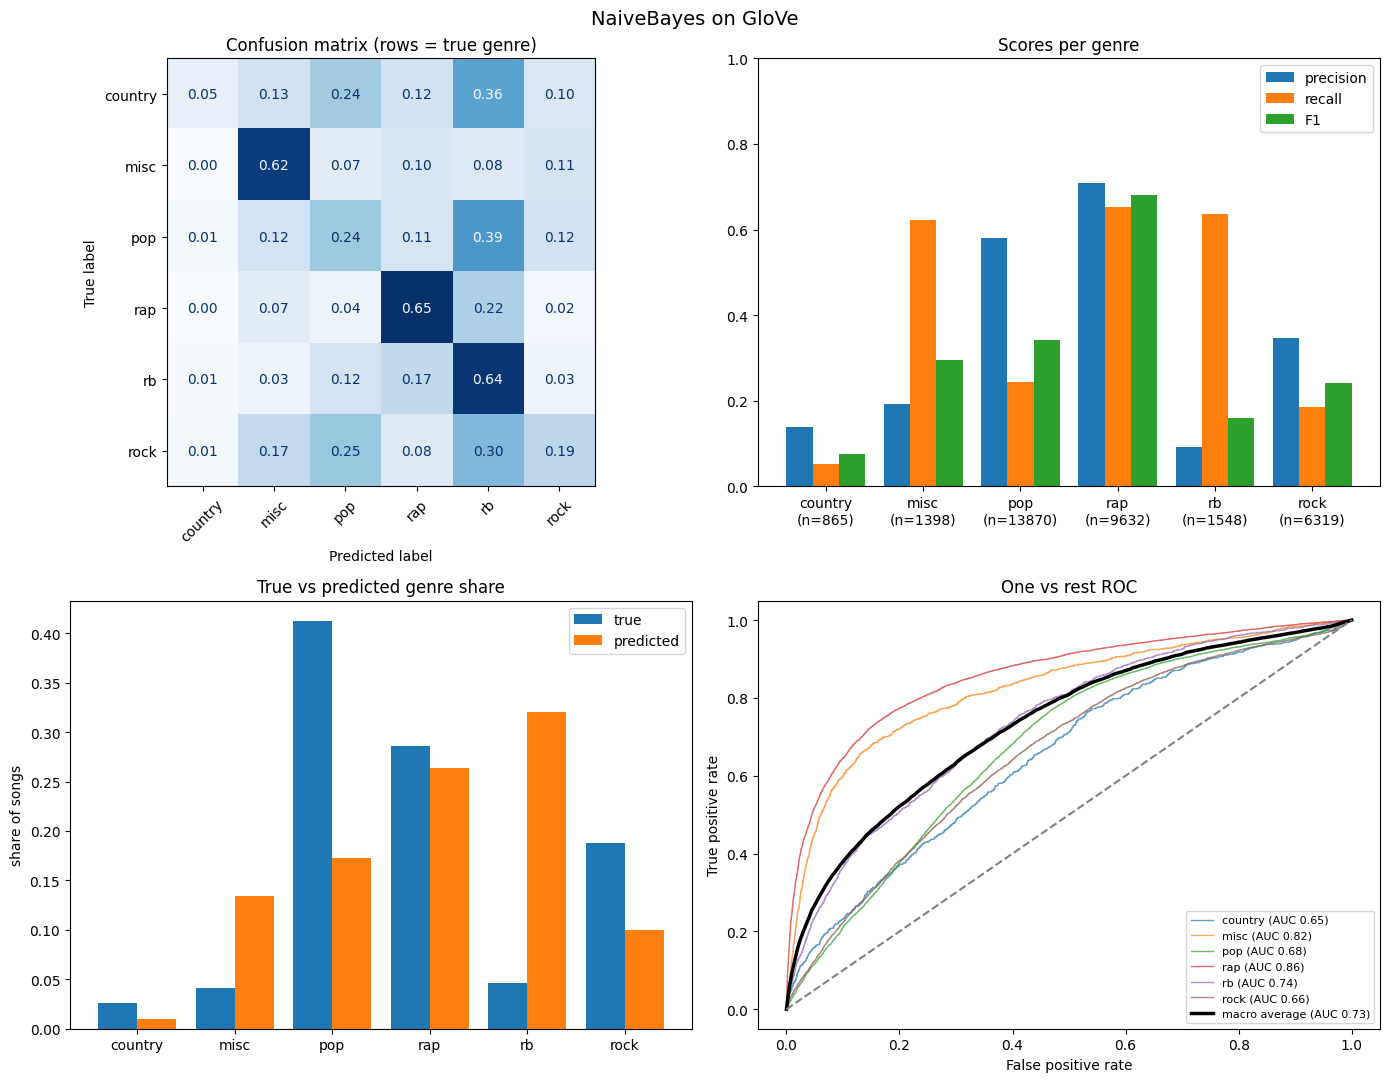

train accuracy: 0.390
val accuracy:   0.383  (always guessing the biggest genre: 0.412)
macro F1:       0.339
weighted F1:    0.370
              precision    recall  f1-score   support

     country       0.07      0.70      0.13       865
        misc       0.29      0.59      0.39      1398
         pop       0.58      0.06      0.10     13870
         rap       0.80      0.74      0.77      9632
          rb       0.16      0.43      0.23      1548
        rock       0.38      0.46      0.42      6319

    accuracy                           0.38     33632
   macro avg       0.38      0.50      0.34     33632
weighted avg       0.56      0.38      0.37     33632



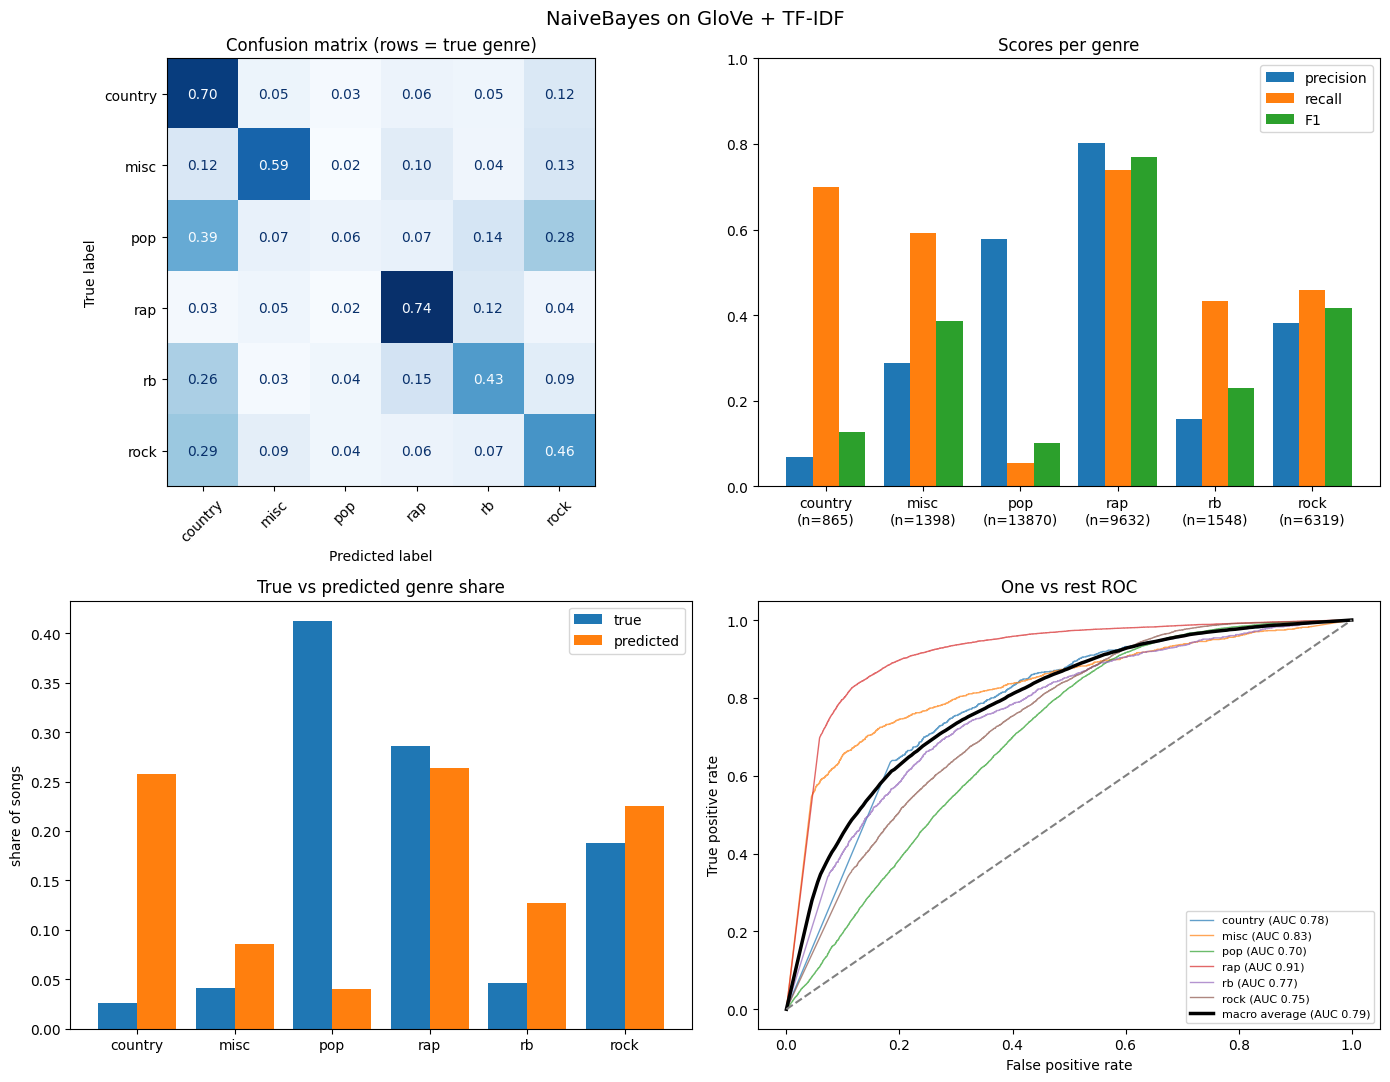

In [ ]:
for fs_key in feature_sets:
    print()
    evaluate(fs_key, "NaiveBayes")

### Logistic Regression

train accuracy: 0.424
val accuracy:   0.425  (always guessing the biggest genre: 0.412)
macro F1:       0.371
weighted F1:    0.434
              precision    recall  f1-score   support

     country       0.10      0.58      0.17       865
        misc       0.27      0.65      0.38      1398
         pop       0.63      0.15      0.25     13870
         rap       0.83      0.73      0.78      9632
          rb       0.15      0.56      0.23      1548
        rock       0.39      0.45      0.42      6319

    accuracy                           0.43     33632
   macro avg       0.39      0.52      0.37     33632
weighted avg       0.59      0.43      0.43     33632



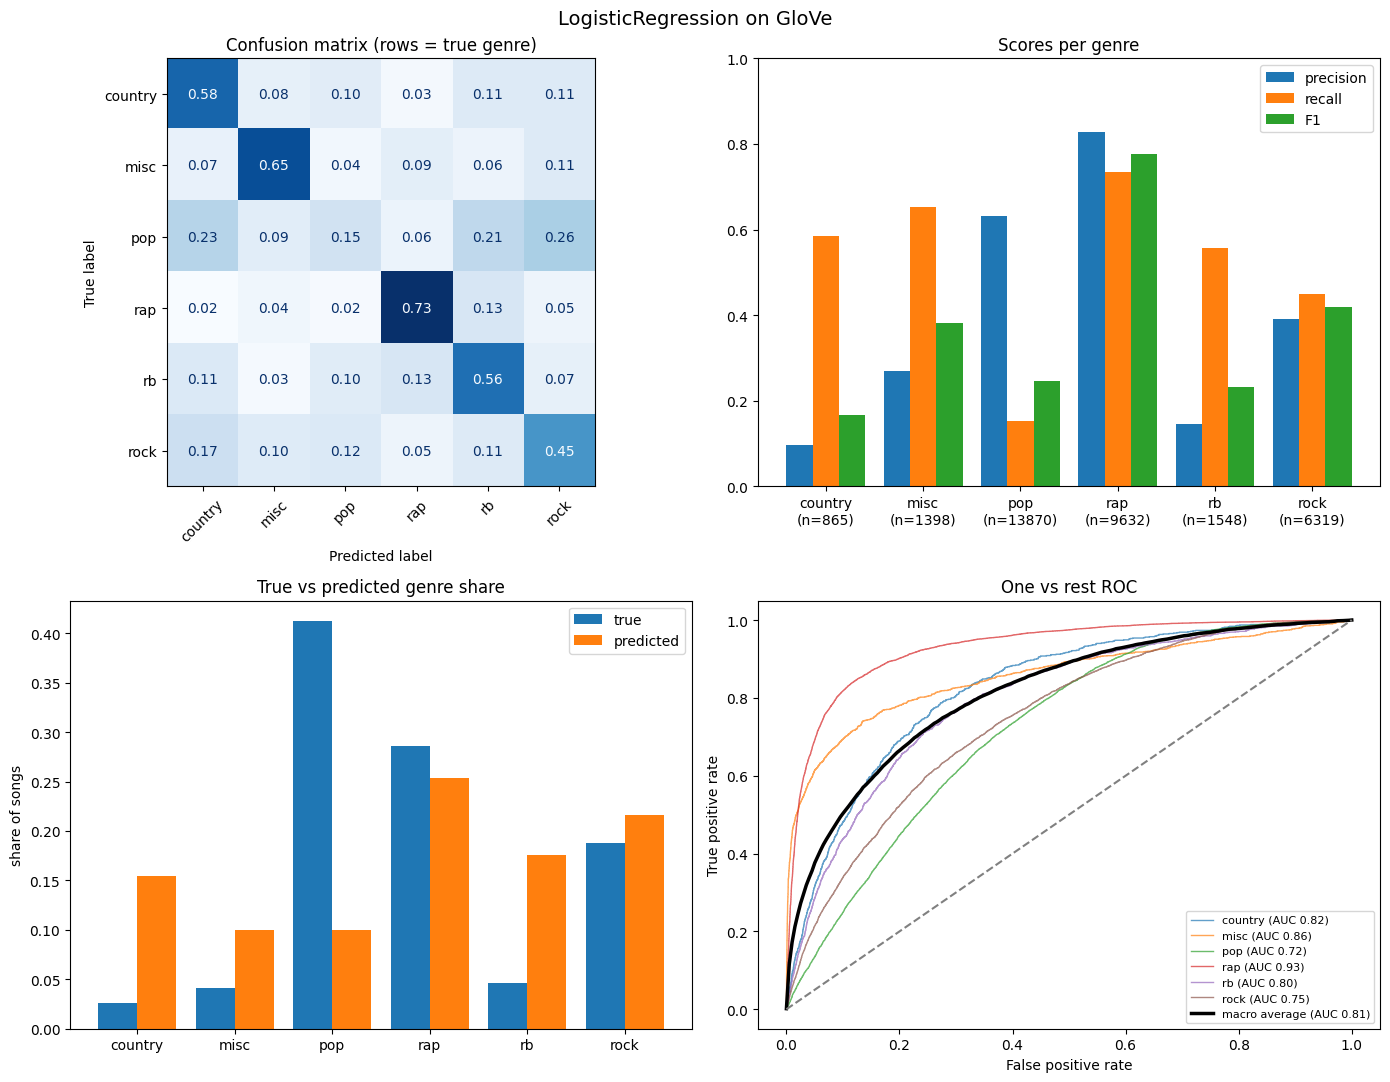

train accuracy: 0.512
val accuracy:   0.492  (always guessing the biggest genre: 0.412)
macro F1:       0.425
weighted F1:    0.509
              precision    recall  f1-score   support

     country       0.13      0.64      0.21       865
        misc       0.30      0.65      0.41      1398
         pop       0.67      0.25      0.37     13870
         rap       0.88      0.77      0.82      9632
          rb       0.18      0.55      0.27      1548
        rock       0.42      0.52      0.46      6319

    accuracy                           0.49     33632
   macro avg       0.43      0.56      0.42     33632
weighted avg       0.63      0.49      0.51     33632



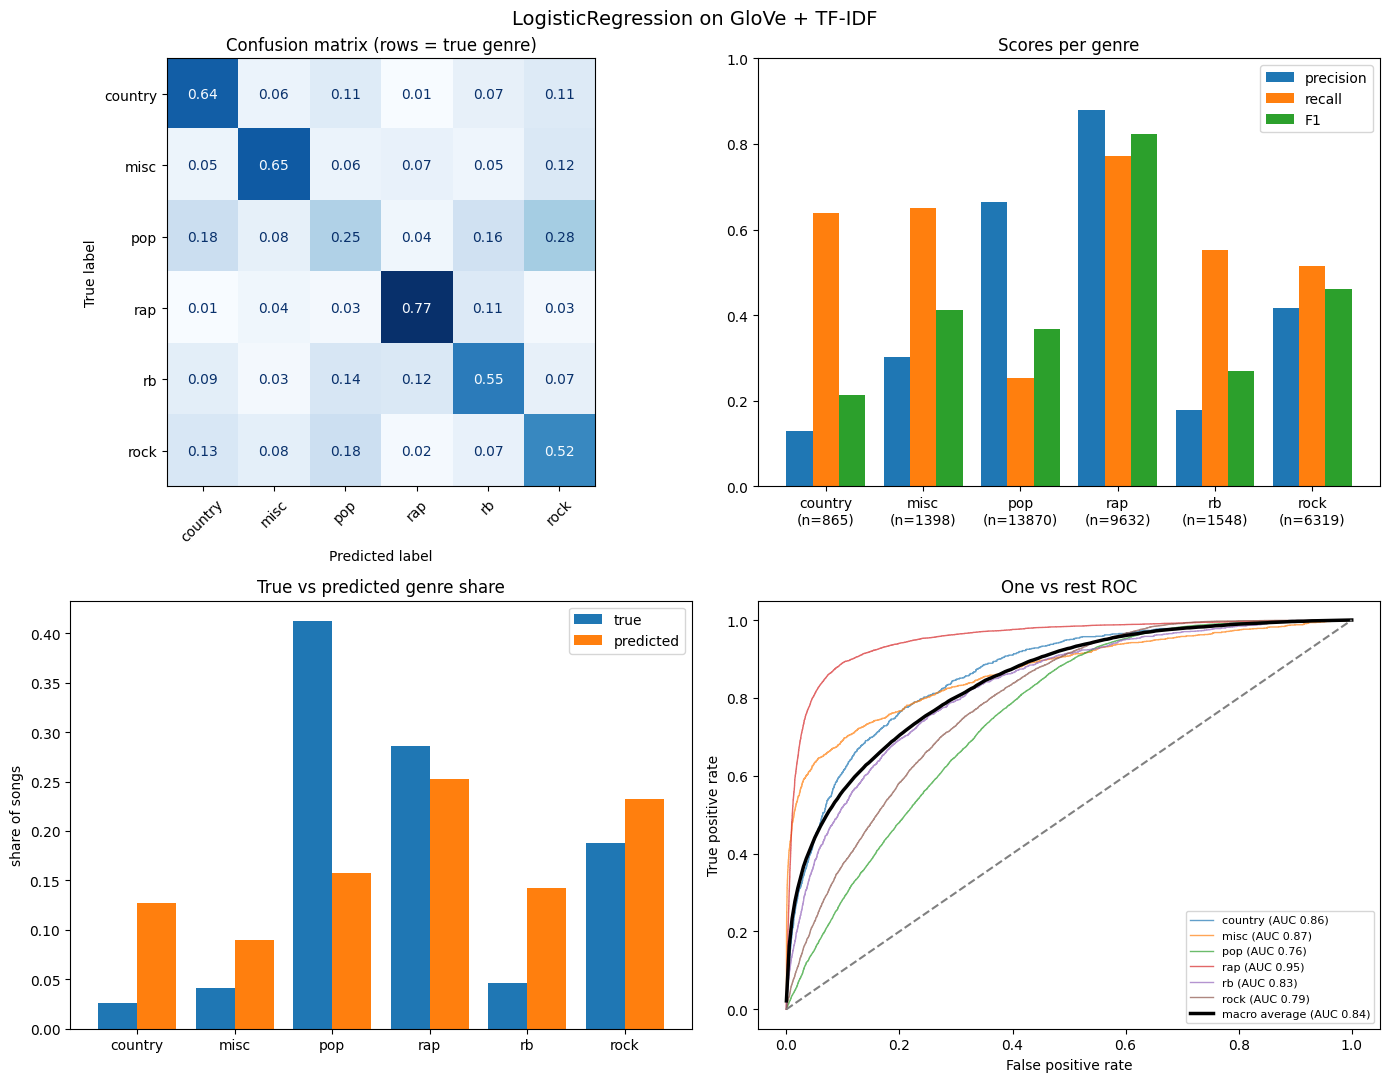

In [14]:
for fs_key in feature_sets:
    evaluate(fs_key, "LogisticRegression")

## Comparison of the Feature Sets

All eight runs side by side, sorted by macro F1. The table after it compares the two feature sets per model: the `gain` columns are the change from adding the TF-IDF features to the GloVe vectors (positive means TF-IDF helps).

In [15]:
results = pl.DataFrame([{"features": labels[fs], "model": m,
                         "train_accuracy": r["train_accuracy"], **scores[(fs, m)],
                         "fit_seconds": r["fit_seconds"]}
                        for (fs, m), r in runs.items()])

results.with_columns(pl.col(pl.Float64).round(3)).sort("macro_f1", descending=True)

features,model,train_accuracy,accuracy,macro_f1,weighted_f1,fit_seconds
str,str,f64,f64,f64,f64,f64
"""GloVe + TF-IDF""","""HistGradientBoosting""",0.6,0.528,0.457,0.543,182.8
"""GloVe + TF-IDF""","""RandomForest""",0.913,0.629,0.452,0.613,54.7
"""GloVe""","""RandomForest""",0.923,0.619,0.445,0.6,38.6
"""GloVe + TF-IDF""","""LogisticRegression""",0.512,0.492,0.425,0.509,745.5
"""GloVe""","""HistGradientBoosting""",0.515,0.462,0.402,0.474,5.9
"""GloVe""","""LogisticRegression""",0.424,0.425,0.371,0.434,20.4
"""GloVe + TF-IDF""","""NaiveBayes""",0.39,0.383,0.339,0.37,1.3
"""GloVe""","""NaiveBayes""",0.378,0.379,0.299,0.403,0.2


In [16]:
def pick(fs_key, suffix):
    return (results.filter(pl.col("features") == labels[fs_key])
                   .select("model", pl.col("accuracy").alias(f"accuracy_{suffix}"),
                           pl.col("macro_f1").alias(f"macro_f1_{suffix}")))

comparison = (pick("glove", "glove").join(pick("glove_tfidf", "tfidf"), on="model")
              .with_columns(accuracy_gain=pl.col("accuracy_tfidf") - pl.col("accuracy_glove"),
                            macro_f1_gain=pl.col("macro_f1_tfidf") - pl.col("macro_f1_glove"))
              .with_columns(pl.col(pl.Float64).round(3)))
comparison

model,accuracy_glove,macro_f1_glove,accuracy_tfidf,macro_f1_tfidf,accuracy_gain,macro_f1_gain
str,f64,f64,f64,f64,f64,f64
"""HistGradientBoosting""",0.462,0.402,0.528,0.457,0.066,0.054
"""RandomForest""",0.619,0.445,0.629,0.452,0.01,0.007
"""NaiveBayes""",0.379,0.299,0.383,0.339,0.005,0.039
"""LogisticRegression""",0.425,0.371,0.492,0.425,0.066,0.054


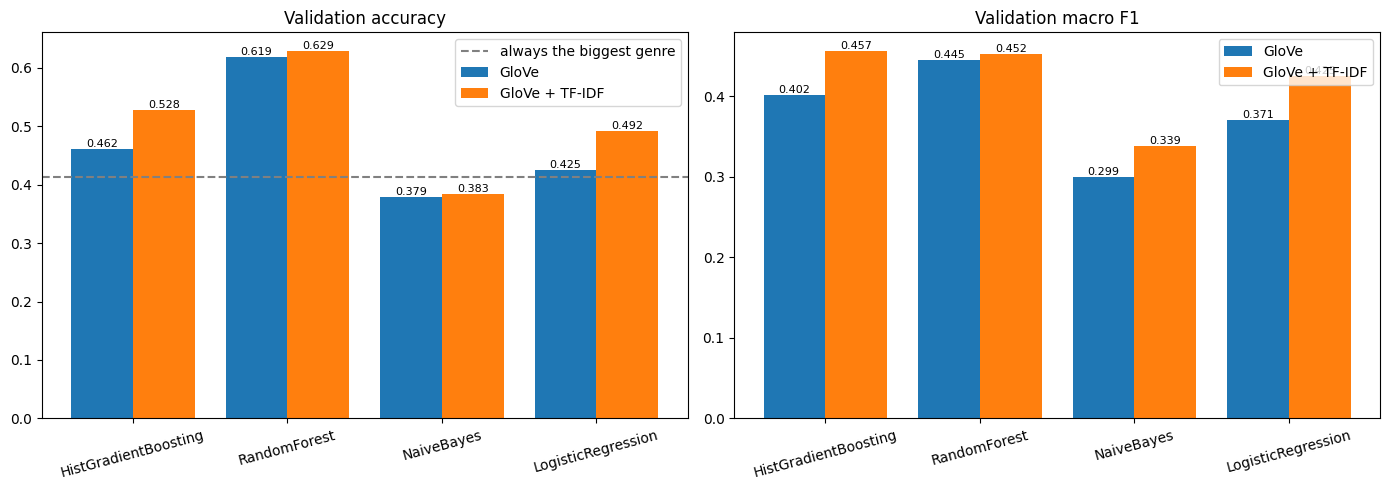

In [17]:
majority = float(np.mean(y_val == genres[np.argmax([np.sum(y_val == g) for g in genres])]))
x = np.arange(len(model_keys))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Validation accuracy", "Validation macro F1"]):
    for offset, fs_key in zip([-0.2, 0.2], feature_sets):
        values = [scores[(fs_key, m)][metric] for m in model_keys]
        bars = ax.bar(x + offset, values, 0.4, label=labels[fs_key])
        ax.bar_label(bars, fmt="%.3f", fontsize=8)
    if metric == "accuracy":
        ax.axhline(majority, color="gray", ls="--", label="always the biggest genre")
    ax.set_xticks(x, model_keys, rotation=15)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

### Which Genres Profit from TF-IDF?

The change in F1 per genre when TF-IDF is added to the GloVe vectors (blue: TF-IDF better, red: GloVe alone better). A model can gain on average, while still getting worse on single genres, which the overall scores hide.

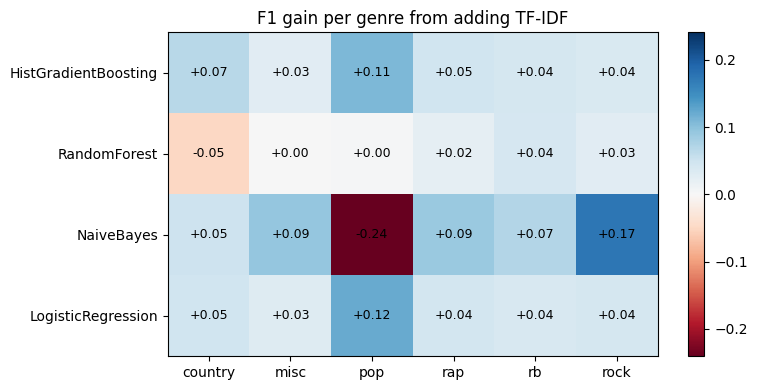

In [18]:
def f1_per_genre(fs_key, m_key):
    pred = genres[runs[(fs_key, m_key)]["proba"].argmax(axis=1)]
    return precision_recall_fscore_support(y_val, pred, labels=genres, zero_division=0)[2]

gain = np.array([f1_per_genre("glove_tfidf", m) - f1_per_genre("glove", m) for m in model_keys])
limit = max(abs(gain).max(), 0.05)

fig, ax = plt.subplots(figsize=(8, 4))
image = ax.imshow(gain, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(genres)), genres)
ax.set_yticks(range(len(model_keys)), model_keys)
for i in range(gain.shape[0]):
    for j in range(gain.shape[1]):
        ax.text(j, i, f"{gain[i, j]:+.2f}", ha="center", va="center", fontsize=9)
ax.set_title("F1 gain per genre from adding TF-IDF")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## Which Features Does the Random Forest Use?

The impurity based feature importances of the random forest trained on `GloVe + TF-IDF`, as a look at what the model relies on. If the 1000 TF-IDF columns (97.6% of the features) carry only a small share of the importance, the 25 GloVe dimensions do most of the work, and the gain from TF-IDF is expected to be small. Impurity importances favour features with many distinct values, so they are a rough guide, not a proof.

TF-IDF columns: 97.6% of the features, 55.8% of the importance
GloVe columns:  2.4% of the features, 44.2% of the importance


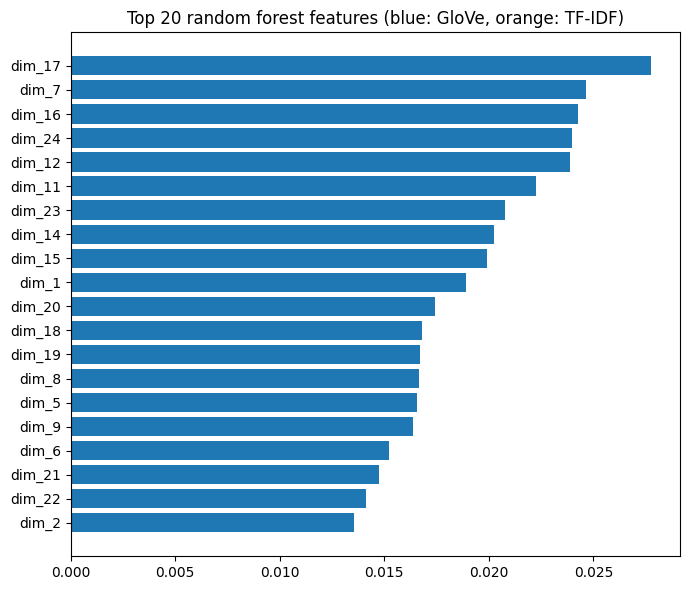

In [19]:
importance = importances["glove_tfidf"]
names = np.array(feature_names["glove_tfidf"])
is_tfidf = np.char.startswith(names, "tfidf_")

print(f"TF-IDF columns: {is_tfidf.mean():.1%} of the features, {importance[is_tfidf].sum() / importance.sum():.1%} of the importance")
print(f"GloVe columns:  {(~is_tfidf).mean():.1%} of the features, {importance[~is_tfidf].sum() / importance.sum():.1%} of the importance")

top = np.argsort(importance)[::-1][:20][::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(names[top], importance[top], color=["tab:orange" if is_tfidf[i] else "tab:blue" for i in top])
ax.set_title("Top 20 random forest features (blue: GloVe, orange: TF-IDF)")
plt.tight_layout()
plt.show()

## Reading the Results

- **Accuracy vs macro F1.** A model that mostly predicts the big genres can reach a decent accuracy and still ignore the small ones. The comparison is therefore based on macro F1, and the accuracy only counts if it is clearly above the biggest genre baseline.
- **Training vs validation accuracy.** A random forest with a training accuracy close to 1 and a much lower validation accuracy memorises the training songs. A gap that is larger with TF-IDF than without it means the extra columns mainly gave the model more to overfit.
- **The effect of TF-IDF.** The gain tables and the per genre heatmap show where the 1000 extra word weights help. Averaged GloVe vectors blur which words a song contains, TF-IDF keeps the most frequent terms explicitly, so a gain is most likely for genres with a distinctive vocabulary.
- **Linear vs tree models.** Logistic regression shows how much of the signal a linear boundary captures. If the tree models are clearly better, the relation between the features and the genre is not linear.